### Task 1: Apply Morphological Operations

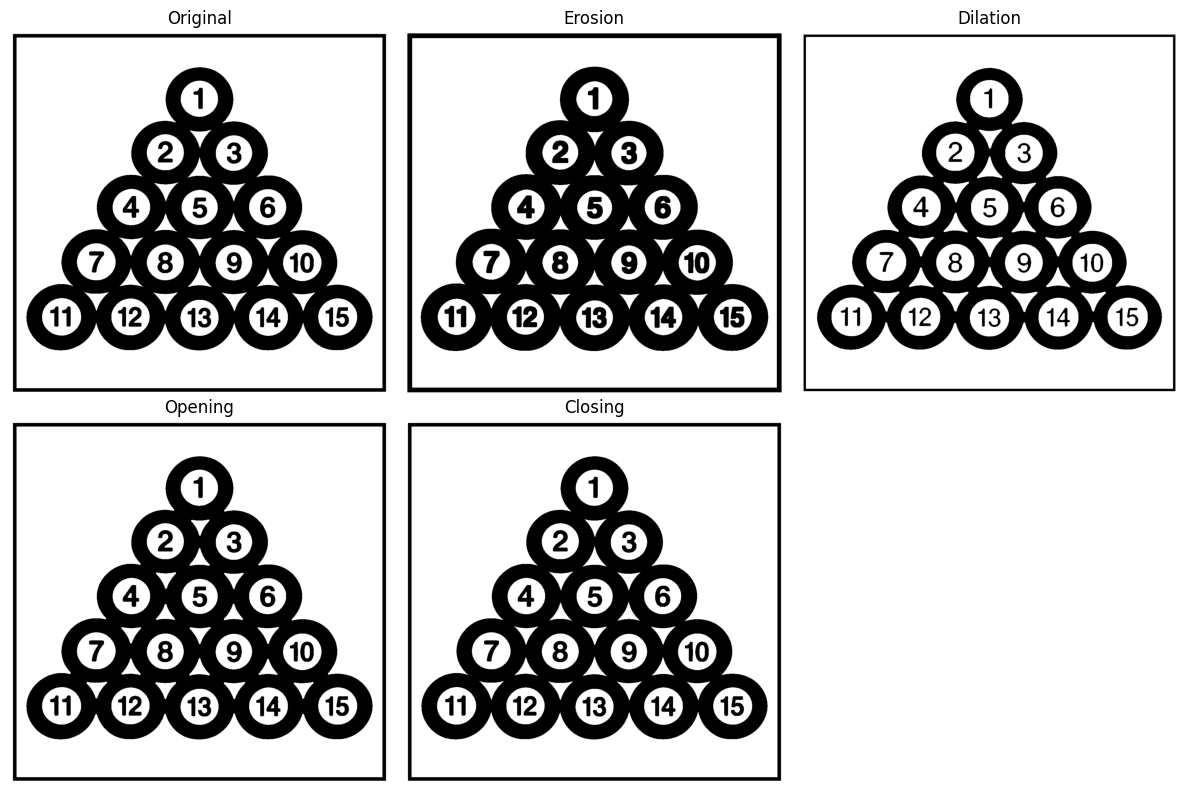

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load image
img = cv2.imread("balls.png", 0)

# 2. Convert to binary
_, binary = cv2.threshold(
    img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# 3. Define 5x5 kernel
kernel = np.ones((5, 5), np.uint8)

# 4. Apply morphological operations
erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# 5. Display original and results
images = [binary, erosion, dilation, opening, closing]
titles = ["Original", "Erosion", "Dilation", "Opening", "Closing"]

plt.figure(figsize=(12, 8))

for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

### Task 2: Experiment with Structuring Elements

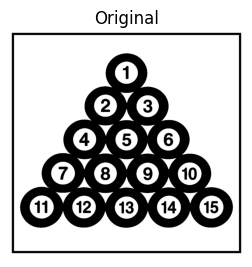

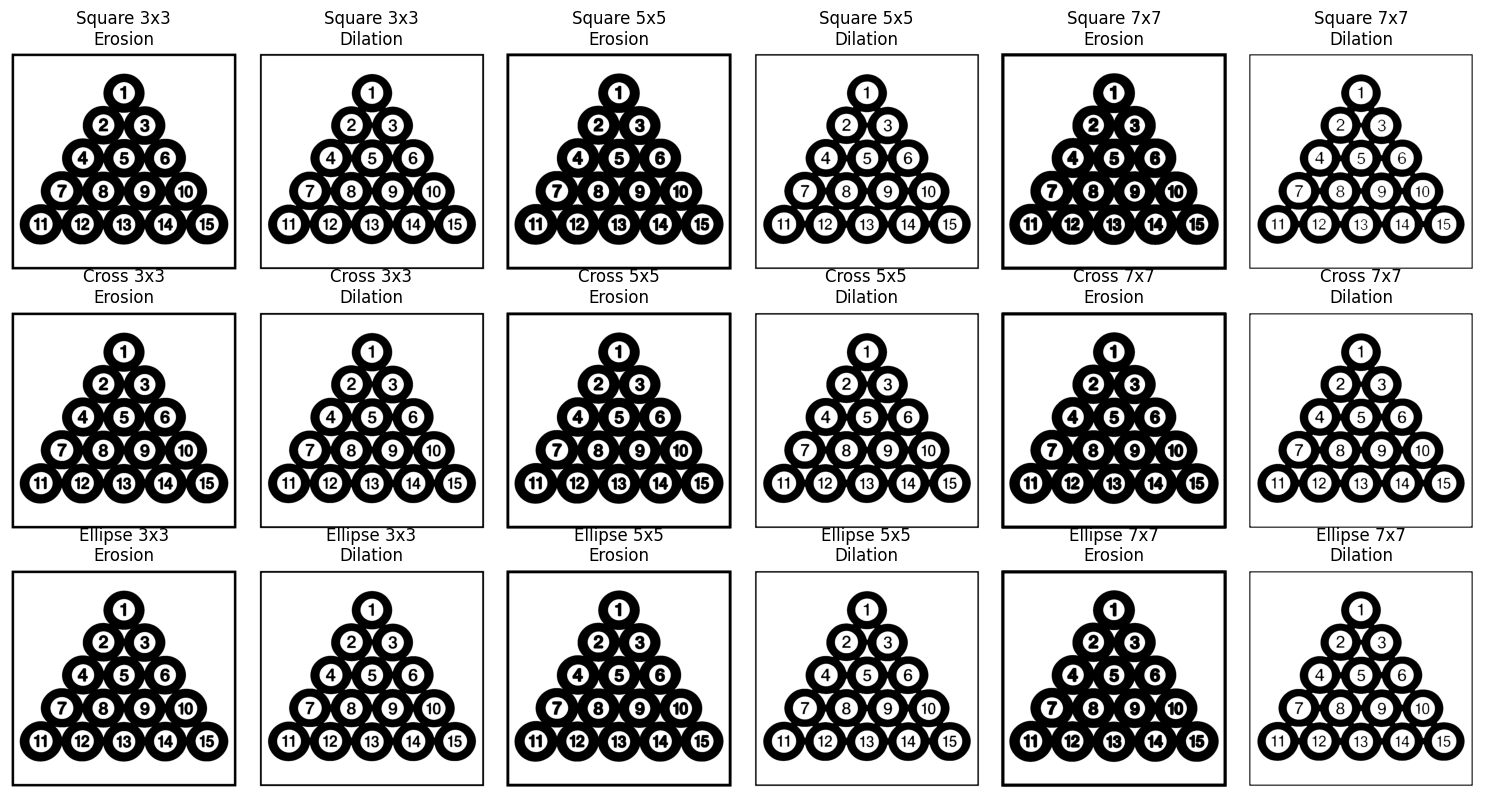

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load image
img = cv2.imread("balls.png", 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Kernel shapes and sizes
shapes = {
    "Square": cv2.MORPH_RECT,
    "Cross": cv2.MORPH_CROSS,
    "Ellipse": cv2.MORPH_ELLIPSE
}

sizes = [3, 5, 7]

# Display original once
plt.figure(figsize=(3, 3))
plt.imshow(binary, cmap="gray")
plt.title("Original")
plt.axis("off")
plt.show()

# Compare results in one compact figure
fig, axes = plt.subplots(3, 6, figsize=(15, 8))

for i, (name, shape) in enumerate(shapes.items()):
    for j, size in enumerate(sizes):

        kernel = cv2.getStructuringElement(shape, (size, size))

        erosion = cv2.erode(binary, kernel)
        dilation = cv2.dilate(binary, kernel)

        axes[i, j*2].imshow(erosion, cmap="gray")
        axes[i, j*2].set_title(f"{name} {size}x{size}\nErosion")

        axes[i, j*2+1].imshow(dilation, cmap="gray")
        axes[i, j*2+1].set_title(f"{name} {size}x{size}\nDilation")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()